<a href="https://colab.research.google.com/github/Nico-Araujo/Enterprise-Challenge/blob/main/notebooks/CardioIA_Fase6_Modelo_Preditivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💓 CardioIA - Fase 6: Coração Sob Controle

**Equipe:** Nicolas Antonio Silva Araujo (RM 566307) e Vitória Pereira Bagatin (RM 566519).

Este notebook contém geração da base sintética oficial (5.000 registros; seed 42), preparação, divisão estratificada 70/30, treinamento supervisionado, avaliação, salvamento e inferência de um novo caso. Funciona de forma independente do repositório privado: pode ser enviado ao Google Colab sem clonar o GitHub.

**Escopo:** demonstração acadêmica. O alvo é `pico_risco`, criado por regras do enunciado, e não um desfecho clínico observado. O notebook avalia o ML; os agentes do OpenAI Agents SDK são implementados separadamente em `src/cardioia`.


### Preparação no Colab

Execute primeiro a célula de dependências. Se ela instalar ou trocar pacotes, **reinicie a sessão** em **Ambiente de execução (Runtime) > Reiniciar sessão (Restart session)** e execute novamente desde o início. A interrupção com essa orientação após instalar é intencional: evita misturar o NumPy antigo em memória com os arquivos novos. Use reiniciar sessão, sem excluir o ambiente. Quando aparecer **Ambiente verificado**, prossiga com o treino e a gravação.


In [ ]:
import importlib
import importlib.metadata
import subprocess
import sys

versions = {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}
modules = {'numpy': 'numpy', 'pandas': 'pandas', 'scikit-learn': 'sklearn', 'joblib': 'joblib', 'matplotlib': 'matplotlib'}
restart_message = (
    'PREPARAÇÃO DO AMBIENTE: reinicie a sessão antes de continuar. '
    'No Colab: Ambiente de execução (Runtime) > Reiniciar sessão (Restart session). '
    'Depois execute todas as células novamente, desde o início. '
    'Não use Desconectar e excluir ambiente de execução, pois isso remove os pacotes instalados.'
)
missing = []
for package, expected in versions.items():
    try:
        if importlib.metadata.version(package) != expected:
            missing.append(package)
    except importlib.metadata.PackageNotFoundError:
        missing.append(package)
if missing:
    # Instala o conjunto fixado em uma única resolução do pip.
    # Bibliotecas nativas já carregadas não são substituídas na memória.
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet',
        *[f'{package}=={expected}' for package, expected in versions.items()],
    ])
    raise RuntimeError('Instalação concluída. ' + restart_message)

# Também detecta uma sessão que executou a antiga célula de instalação.
stale = [package for package, module in modules.items()
         if module in sys.modules
         and getattr(sys.modules[module], '__version__', versions[package]) != versions[package]]
if stale:
    raise RuntimeError('Versões antigas ainda carregadas: ' + ', '.join(stale) + '. ' + restart_message)
try:
    for module in ['numpy.testing', 'scipy.sparse', 'pandas', 'matplotlib.pyplot', 'sklearn.model_selection', 'joblib']:
        importlib.import_module(module)
except (ImportError, AttributeError, ValueError) as exc:
    raise RuntimeError(f'Importação inconsistente ({type(exc).__name__}: {exc}). ' + restart_message) from None

print('Ambiente verificado. Python:', sys.version.split()[0])
print('Dependências do experimento:', versions)
print('SciPy:', importlib.metadata.version('scipy'))
print('As demais células já podem ser executadas.')


Ambiente verificado. Python: 3.13.16
Dependências do experimento: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}
SciPy: 1.16.3
As demais células já podem ser executadas.


## 1. Geração e inspeção da base

O gerador preserva exatamente as distribuições e os limites fornecidos. `risk_score` apenas constrói o rótulo: não é uma variável explicativa. Cada linha combina variáveis de um caso simulado e de contexto operacional; não representa uma série temporal.


In [ ]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

ROOT = Path.cwd()
for folder in ['data', 'models', 'docs/metricas']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
FEATURES = ['idade_media', 'carga_sistema', 'tempo_espera', 'fc_media', 'spo2_media', 'pa_sistolica', 'temperatura', 'densidade_eventos', 'eventos_24h', 'disponibilidade_recursos']
TARGET, SEED = 'pico_risco', 42


In [ ]:
def generate_dataset(n: int = 5000, seed: int = SEED) -> pd.DataFrame:
    if n < 1:
        raise ValueError("O número de registros deve ser positivo.")
    # RandomState reproduz np.random.seed(42) sem alterar o RNG de outros módulos.
    rng = np.random.RandomState(seed)
    df = pd.DataFrame({
        "idade_media": rng.normal(55, 12, n).clip(18, 90),
        "carga_sistema": rng.uniform(30, 100, n),
        "tempo_espera": rng.normal(45, 20, n).clip(5, 180),
        "fc_media": rng.normal(85, 15, n).clip(50, 150),
        "spo2_media": rng.normal(95, 3, n).clip(70, 100),
        "pa_sistolica": rng.normal(125, 20, n).clip(80, 200),
        "temperatura": rng.normal(24, 5, n).clip(10, 40),
        "densidade_eventos": rng.poisson(3, n),
        "eventos_24h": rng.poisson(2, n),
        "disponibilidade_recursos": rng.uniform(20, 100, n),
    })
    risk_score = (
        (df["carga_sistema"] > 80).astype(int)
        + (df["tempo_espera"] > 60).astype(int)
        + (df["spo2_media"] < 92).astype(int)
        + (df["fc_media"] > 110).astype(int)
        + (df["eventos_24h"] > 4).astype(int)
        + (df["disponibilidade_recursos"] < 40).astype(int)
    )
    df[TARGET] = (risk_score >= 2).astype(int)
    return df


df = generate_dataset()
assert df.shape == (5000, 11) and not df.isna().any().any()
df.to_csv(ROOT / 'data/base_sintetica.csv', index=False)
display(df.head())
display(df.describe())
print('Classes:', df[TARGET].value_counts().sort_index().to_dict())


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,pico_risco
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,55.058872,64.637825,45.243077,85.305275,94.920231,124.893487,24.003366,2.998000,1.99240,60.271841,0.265800
std,11.925581,19.987923,19.383549,14.897908,2.874954,19.529416,5.080669,1.731876,1.41843,23.030132,0.441802
min,18.000000,30.003698,5.000000,50.000000,83.430874,80.000000,10.000000,0.000000,0.00000,20.035489,0.000000
25%,47.105140,47.604462,31.838260,75.000614,92.900337,111.201401,20.514351,2.000000,1.00000,40.186700,0.000000
50%,55.161587,64.430649,45.143356,85.218044,94.984043,125.058077,23.967477,3.000000,2.00000,60.871675,0.000000
75%,62.992127,81.684947,58.278490,95.604945,97.009198,138.054290,27.506223,4.000000,3.00000,80.393247,1.000000
max,90.000000,99.977124,113.578210,150.000000,100.000000,198.832490,40.000000,13.000000,9.00000,99.989376,1.000000


Classes: {0: 3671, 1: 1329}


## 2. Preparação e divisão treino/teste

Usamos as dez variáveis originais e mantemos `pico_risco` fora de X. A separação estratificada é reprodutível. Não há imputação, pois o gerador não produz valores ausentes. A padronização é ajustada dentro do pipeline, exclusivamente sobre os dados de treino.


In [ ]:
X, y = df.loc[:, FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
assert not set(X_train.index) & set(X_test.index)
assert list(X_train.columns) == FEATURES
print(f'Treino: {len(X_train)}; teste: {len(X_test)}')
print('Classes de treino:', y_train.value_counts().sort_index().to_dict())
print('Classes de teste:', y_test.value_counts().sort_index().to_dict())


Treino: 3500; teste: 1500
Classes de treino: {0: 2570, 1: 930}
Classes de teste: {0: 1101, 1: 399}


## 3. Classificador supervisionado

O algoritmo é a regressão logística, apresentada na Fase 6, capítulo 02, com `predict_proba` e persistência por `joblib`. Foi adaptada de classificação de texto para atributos numéricos. A divisão estratificada e a matriz de confusão seguem os conceitos do capítulo 08. A normalização dos atributos é tratada nas disciplinas anteriores.

Esta é uma primeira referência simples, interpretável e reprodutível. Não usamos as regras que criam o alvo como features nem otimizamos o modelo com base nos resultados do conjunto de teste. O limiar operacional adotado é 0,5: `alto` quando p ≥ 0,5; `baixo` caso contrário.


In [ ]:
model = Pipeline([('scaler', StandardScaler()), ('classifier', LogisticRegression(max_iter=1000, random_state=SEED))])
model.fit(X_train, y_train)
np.testing.assert_allclose(model['scaler'].mean_, X_train.mean().to_numpy())
predictions = model.predict(X_test)
print('Treinamento concluído sem ajuste sobre o teste.')


Treinamento concluído sem ajuste sobre o teste.


## 4. Avaliação no teste reservado

A acurácia deve ser interpretada junto aos erros e à distribuição de classes. Linhas da matriz: classe verdadeira; colunas: classe prevista; ordem `[0, 1]` (sem pico, pico). Os números abaixo são calculados pela execução, sem valores fixos.


Acurácia: 81.93%
Matriz de confusão: [[1013, 88], [183, 216]]
              precision    recall  f1-score   support

           0       0.85      0.92      0.88      1101
           1       0.71      0.54      0.61       399

    accuracy                           0.82      1500
   macro avg       0.78      0.73      0.75      1500
weighted avg       0.81      0.82      0.81      1500

TN=1013; FP=88; FN=183; TP=216


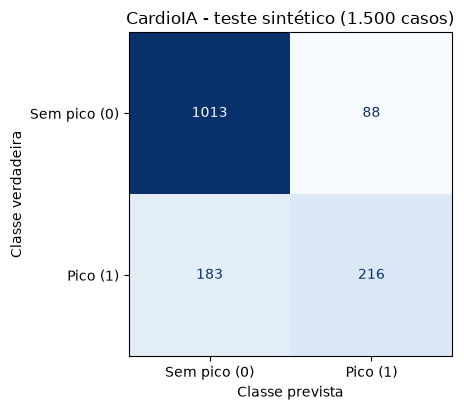

1065

In [ ]:
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
report = classification_report(y_test, predictions, output_dict=True, zero_division=0)
metrics = {'algoritmo': 'StandardScaler + LogisticRegression', 'seed': SEED, 'registros': len(df), 'treino': len(X_train), 'teste': len(X_test), 'acuracia': float(accuracy_score(y_test, predictions)), 'matriz_confusao': matrix.tolist(), 'ordem_classes': [0, 1], 'relatorio_classificacao': report, 'distribuicao_classes': {str(k): int(v) for k,v in df[TARGET].value_counts().sort_index().items()}}
print(f'Acurácia: {metrics["acuracia"]:.2%}')
print('Matriz de confusão:', matrix.tolist())
print(classification_report(y_test, predictions, zero_division=0))
tn, fp, fn, tp = matrix.ravel()
print(f'TN={tn}; FP={fp}; FN={fn}; TP={tp}')
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ConfusionMatrixDisplay(matrix, display_labels=['Sem pico (0)', 'Pico (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('CardioIA - teste sintético (1.500 casos)')
ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe verdadeira')
fig.tight_layout()
fig.savefig(ROOT / 'docs/metricas/matriz_confusao.png', dpi=180)
plt.show()
(ROOT / 'docs/metricas/avaliacao.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


### Interpretação e limitações

Com as versões registradas, a referência produz 81,93% de acurácia, 88 falsos positivos e 183 falsos negativos. O recall de pico é 54,14%: muitos casos positivos deixam de ser identificados pelo classificador linear. As condições do rótulo são limiares discretos combinados; a regressão logística sobre as variáveis contínuas não reproduz perfeitamente essas descontinuidades.

A classe 0 é majoritária (73,42%); prever apenas essa classe já alcançaria essa acurácia. Portanto, acurácia isolada é insuficiente. As probabilidades não foram calibradas para uso clínico; 99% em um caso sintético não equivale a 99% de chance de evento cardíaco real. Os protocolos também são simulados. Melhorias exigiriam dados representativos, avaliação externa, análise de recall e estudo de outros algoritmos ensinados, usando validação separada sem reutilizar o teste para escolher parâmetros.


## 5. Persistência de modelo e transformações

O artefato inclui o pipeline completo, os nomes e a ordem das features, limiar, versões e índices do split. No Colab, baixe `models/pico_risco.joblib` para integração. Carregue apenas artefatos de origem confiável, pois `joblib` usa serialização Python.


In [ ]:
metadata = {'features': FEATURES, 'target': TARGET, 'risk_threshold': 0.5, 'seed': SEED, 'test_size': 0.3, 'python': platform.python_version(), 'versions': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'joblib']}, 'training_indices': X_train.index.tolist(), 'test_indices': X_test.index.tolist(), 'classificacao': 'alto se probabilidade >= 0.5; baixo caso contrário'}
joblib.dump({'pipeline': model, 'metadata': metadata}, ROOT / 'models/pico_risco.joblib', compress=3)
(ROOT / 'models/metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Modelo e metadados salvos em models/.')


Modelo e metadados salvos em models/.


## 6. Novo caso usando o modelo recarregado

O nome canônico é `disponibilidade_recursos`; corrigimos o espaço do exemplo do enunciado. O valor `0.91` do texto é ilustrativo. A saída abaixo vem do modelo salvo.


In [ ]:
novo_caso = pd.DataFrame([{'idade_media': 62, 'carga_sistema': 92, 'tempo_espera': 75, 'fc_media': 118, 'spo2_media': 89, 'pa_sistolica': 100, 'temperatura': 37.5, 'densidade_eventos': 7, 'eventos_24h': 5, 'disponibilidade_recursos': 25}])
artifact = joblib.load(ROOT / 'models/pico_risco.joblib')
saved = artifact['pipeline']
positive_index = list(saved.classes_).index(1)
probability = float(saved.predict_proba(novo_caso.loc[:, artifact['metadata']['features']])[0, positive_index])
classification = 'alto' if probability >= artifact['metadata']['risk_threshold'] else 'baixo'
assert np.isclose(probability, model.predict_proba(novo_caso.loc[:, FEATURES])[0, positive_index])
print(json.dumps({'probabilidade': probability, 'classificacao_risco': classification}, ensure_ascii=False, indent=2))


{
  "probabilidade": 0.9986424786256043,
  "classificacao_risco": "alto"
}


## Integração com os agentes

A tool `prever_risco` recarrega o mesmo artefato e acessa as features na mesma ordem. A tool de protocolos avalia os dados originais, e o Planejador consolida a saída. O caso acima satisfaz carga > 85, recursos < 30 e densidade > 6; o protocolo de risco sistêmico alto segue a classificação. SPO2 89 não satisfaz SPO2 < 88, portanto não deve sugerir suporte respiratório por essa regra.

Para executar os agentes, use o código do repositório com Qwen3/Ollama local, conforme o README. Não é necessária uma chave OpenAI ou API paga para o notebook de ML nem para o backend local dos agentes.
